# Robustness of the non-learning detectors

**The question:** if the photos get worse (noisy, blurry, dark, partly covered...), how much worse do the non-learning bird detectors get?

**How:** damage the validation images on purpose, run the detectors again, and compare the score before and after.

**Files used**
- `non-learning.py`: the 4 blob detectors (DoG, DoH, MSER, threshold) and the mAP metric
- `cnn_augmentation/corruptions.py`: the image damage. The CNN uses the same file, so both methods are tested on identical images
- `robustness.py`: runs the experiment

The full run takes about an hour, so this notebook loads the saved results from `results_nonlearning/`.

## 1. Setup

In [1]:
import json, os, contextlib, io
import numpy as np
import cv2
import matplotlib.pyplot as plt

import robustness as r
from corruptions import CORRUPTIONS, corrupt
nl = r.nl            # non-learning.py
%matplotlib inline
plt.rcParams["figure.dpi"] = 60

val = nl.load_split("dataset", "val")
print(f"{len(val)} validation images, {sum(len(g) for _, g in val)} birds")
nl.box_size_stats(val);

291 validation images, 1843 birds
bird box size (sqrt area, px): min 7.6  p10 16.9  median 40.2  p90 135.5  max 473.8


Birds are about **40 px** across on average, but range from 8 px to 470 px.

## 2. The damage

7 types, each at 5 levels (1 = mild, 5 = severe). Each image always gets the same random damage (seed = image number), so the comparison with the CNN is fair.

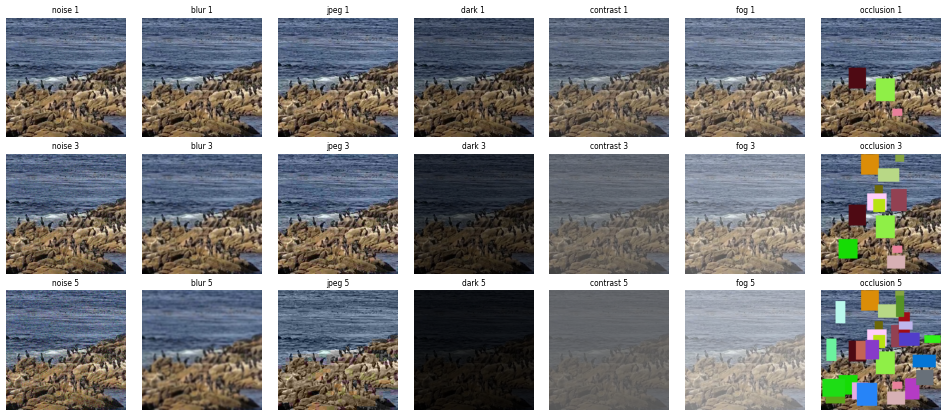

In [2]:
img = r.read_rgb(val[0][0])
fig, axes = plt.subplots(3, 7, figsize=(16, 7))
for col, name in enumerate(CORRUPTIONS):
    for row, level in enumerate([1, 3, 5]):
        axes[row, col].imshow(corrupt(img, name, level, seed=0))
        axes[row, col].set_title(f"{name} {level}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

## 3. The score: mAP@0.5

- A predicted box counts as **correct** if it overlaps a real bird by at least 50%.
- **mAP** combines how many birds were found with how many predictions were wrong.
- 0 = useless, 1 = perfect.

## 4. Step 1: pick the best settings (clean images)

Try every setting combination for each detector on undamaged validation images and keep the best.
Command: `python robustness.py --tune`

In [3]:
params = json.load(open(r.PARAMS_FILE))
for d, p in params.items():
    print(f"{d:<10} mAP {p['val_map']:.3f}   {p['params']}")

dog        mAP 0.033   {'smallest_sigma_blur': 3.0, 'box_scale': 3.0, 'refine': True}
doh        mAP 0.032   {'smallest_sigma_blur': 3.0, 'box_scale': 3.0, 'refine': False}
mser       mAP 0.002   {'delta': 8, 'min_area': 15}
threshold  mAP 0.005   {'block': 31, 'C': 5}


**Takeaway:** even on clean images the best score is only about **0.03**. The detectors find blobs, and beaches are full of blobs that aren't birds (rocks, shells, foam).

## 5. Step 2: damage the images and score again

The only difference between "before" and "after" is one line in `robustness.py`:

```python
grays = [to_gray(corrupt(im, name, level, seed=i)) for i, im in enumerate(rgbs)]
```
Command: `python robustness.py`

mAP, averaged over levels 1-5

detector     clean     noise      blur      jpeg      dark  contrast       fog occlusion
dog          0.033     0.036     0.035     0.033     0.024     0.024     0.033     0.014
doh          0.032     0.032     0.038     0.032     0.031     0.032     0.032     0.013
mser         0.002     0.002     0.005     0.002     0.001     0.001     0.002     0.001
threshold    0.005     0.005     0.008     0.004     0.005     0.005     0.006     0.002


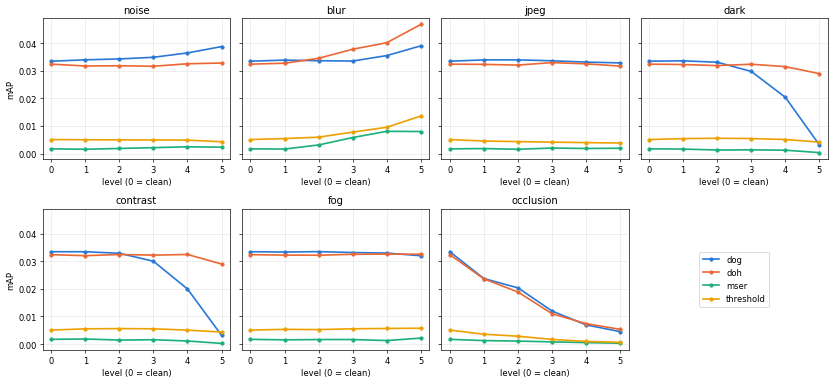

In [4]:
res = json.load(open(os.path.join(r.OUT_DIR, "results_val.json")))
dets = list(res)

print("mAP, averaged over levels 1-5\n")
print(f"{'detector':<11}{'clean':>7}" + "".join(f"{c:>10}" for c in CORRUPTIONS))
for d in dets:
    print(f"{d:<11}{res[d]['clean']:>7.3f}" + "".join(f"{np.mean(res[d][c]):>10.3f}" for c in CORRUPTIONS))

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True)
for ax, c in zip(axes.flat, CORRUPTIONS):
    for colour, d in zip(r.COLOURS, dets):
        ax.plot(range(6), [res[d]["clean"]] + res[d][c], "o-", color=colour, lw=2, ms=4, label=d)
    ax.set_title(c); ax.set_xlabel("level (0 = clean)"); ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("mAP"); axes[1, 0].set_ylabel("mAP")
axes.flat[-1].axis("off")
axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), loc="center")
plt.tight_layout(); plt.show()

**What it shows**
1. **Occlusion** hurts every detector (0.033 → 0.005).
2. **Dark / low contrast** breaks **DoG** (0.033 → 0.003) but not DoH.
3. **Blur** actually **helps DoH** (0.032 → 0.047).
4. **Noise, JPEG, fog** barely matter.

## 6. Before and after

Green = real birds. Red = the detector's top guesses.

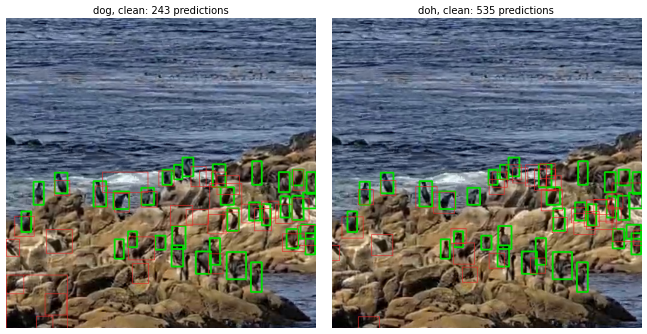

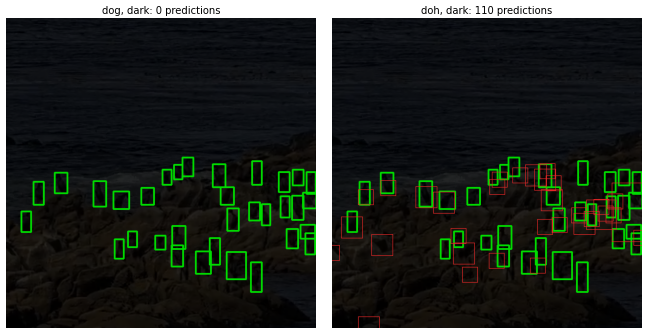

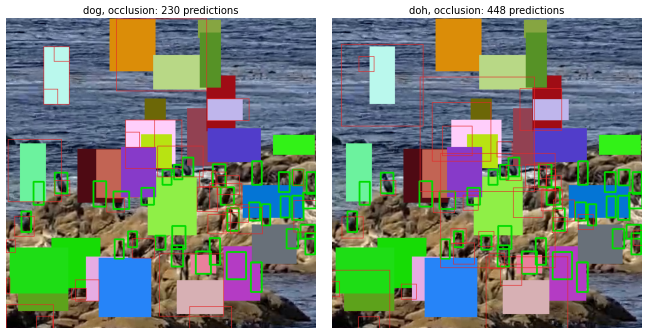

In [5]:
def show(index, corruption=None, level=5):
    path, gt = val[index]
    img = r.read_rgb(path)
    if corruption:
        img = corrupt(img, corruption, level, seed=index)
    gray = r.to_gray(img)
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, d in zip(axes, ["dog", "doh"]):
        (boxes, scores), = r.detect_all(d, params[d]["params"], [gray])[0]
        top = np.argsort(-scores)[:len(gt)]
        drawn = img.copy()
        for x1, y1, x2, y2 in gt.astype(int):
            cv2.rectangle(drawn, (x1, y1), (x2, y2), (0, 220, 0), 2)
        for x1, y1, x2, y2 in boxes[top].astype(int):
            cv2.rectangle(drawn, (x1, y1), (x2, y2), (230, 40, 40), 1)
        ax.imshow(drawn); ax.axis("off")
        ax.set_title(f"{d}, {corruption or 'clean'}: {len(boxes)} predictions")
    plt.tight_layout(); plt.show()

show(0)                  # before
show(0, "dark", 5)       # after: dark
show(0, "occlusion", 5)  # after: occlusion

- On the dark image, **DoG predicts nothing**, even though the birds are still visible.
- The birds are **tall and narrow**, but the detectors always draw **squares**, so many boxes don't overlap enough to count.

## 7. Why does DoG fail on dark images?

**Idea:** DoG throws away any blob weaker than a fixed cut-off (0.02). Darkening makes *every* blob weaker, so they all get thrown away.

**Test:** lower the cut-off by the same amount the image was darkened (×0.15) and see if the score comes back.

In [6]:
p = params["dog"]["params"]
sub = val[:60]
gts = [g for _, g in sub]

def images(cond=None):
    out = []
    for i, (path, _) in enumerate(sub):
        img = r.read_rgb(path)
        if cond:
            img = corrupt(img, *cond, seed=i)
        out.append(r.to_gray(img))
    return out

for label, cond, thr in [("clean,  cut-off 0.02 ", None, 0.02),
                         ("dark 5, cut-off 0.02 ", ("dark", 5), 0.02),
                         ("dark 5, cut-off 0.003", ("dark", 5), 0.003)]:
    preds, _ = r.detect_all("dog", {**p, "thresh": thr}, images(cond))
    print(f"{label}  mAP {r.score(preds, gts):.3f}")

clean,  cut-off 0.02   mAP 0.025


dark 5, cut-off 0.02   mAP 0.001


dark 5, cut-off 0.003  mAP 0.023


**Confirmed.** The score comes back once the cut-off is lowered. The birds didn't disappear; the fixed cut-off threw them away.

**Fix to try next:** stretch each image's contrast before detecting, so dark images look normal to the detector.

## 8. Why does blur help DoH?

**First guess:** blur removes tiny false alarms. **Test:** count predictions and correct ones, clean vs blurred.

In [7]:
def stats(cond=None):
    preds, _ = r.detect_all("doh", params["doh"]["params"], images(cond))
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        ap = nl.average_precision(preds, gts)
    return ap, buf.getvalue().strip()

for label, cond in [("clean ", None), ("blur 3", ("blur", 3)), ("blur 5", ("blur", 5))]:
    ap, info = stats(cond)
    print(f"{label}  mAP {ap:.3f} | {info}")

clean   mAP 0.017 | 399 real birds, 18252 predictions, 110 correct | max recall 0.28, precision at that point 0.006


blur 3  mAP 0.023 | 399 real birds, 19520 predictions, 127 correct | max recall 0.32, precision at that point 0.007


blur 5  mAP 0.020 | 399 real birds, 19427 predictions, 110 correct | max recall 0.28, precision at that point 0.006


**The first guess was wrong.** Blur gives slightly *more* predictions, and *more* correct ones.

**Better explanation (still to test):** blur makes each bird look like a bigger blob, so the box drawn around it gets bigger. The boxes were too small to begin with (the best box size was the largest one we tried), so bigger boxes match more birds.

## 9. Summary

| Finding | Status |
|---|---|
| Detectors are weak even on clean images (≈ 0.03) | measured |
| Occlusion hurts everything | measured |
| DoG breaks on dark images because of a fixed cut-off | **confirmed** |
| Blur helps DoH, probably because boxes get bigger | partly tested |
| Noise, JPEG and fog barely matter | measured |

**Next steps**
1. Contrast stretching before detection, to fix the dark-image problem
2. Try bigger boxes (and non-square ones)
3. Add a HOG + SVM classifier to filter out blobs that aren't birds
4. Put these results next to the CNN results
5. Run once on the test set at the very end: `python robustness.py --split test`